## 결정 트리와 앙상블


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import f1_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
models = {}  # 이름별로 학습한 모델을 저장한다.
model_results = {}  # 모델 이름별 평가 결과를 저장한다.


### 결정 트리는 무엇인가

결정 트리(Decision Tree)는 입력 특성에 대한 조건을 따라 데이터를 나누고, 마지막에 도달한 집단의 학습 결과로 예측하는 모델이다.
예를 들어 `특성 A ≤ 3.5`라는 조건으로 데이터를 두 집단으로 나누고, 각 집단에 다시 조건을 적용할 수 있다.

트리를 구성하는 지점을 노드라고 한다. 시작 노드는 루트, 조건에 따라 나누는 과정은 분기, 더 이상 나누지 않고 예측값을 내는 마지막 노드는 잎이다.
학습할 때 분기 조건과 잎의 예측값을 구하며, 새로운 입력은 정해진 조건을 따라 잎에 도달한다.

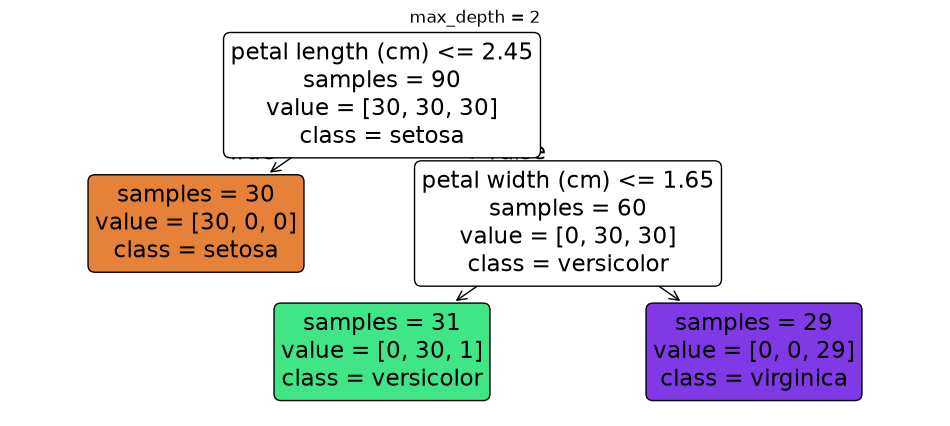


### 트리는 분할 기준을 어떻게 고르는가

분류 트리는 현재 노드에서 나눌 특성과 기준값 후보를 비교해, 같은 클래스의 사례가 더 잘 모이는 분할을 선택한다.

지니 불순도(Gini impurity)는 한 노드에 서로 다른 클래스가 얼마나 섞여 있는지를 나타낸다.
한 클래스만 있으면 0이고, 여러 클래스가 고르게 섞일수록 높다.

트리는 지니 불순도가 낮아지는 방향으로 분할 조건(특성과 기준값)을 선택한다.
선택한 조건으로 나뉜 각 노드에서도 같은 과정을 반복하며, 최대 깊이나 최소 사례 수 등의 조건에 따라 분할을 멈춘다.


### Titanic 생존 예측

승객의 탑승 정보를 입력으로 받아 생존 여부를 예측하는 문제다.
`survived=1`은 생존, `survived=0`은 사망이다. 이 실습의 양성 클래스는 생존이다.

### Titanic 데이터 불러오기

Titanic은 승객 891명의 기록을 담고 있다. 한 행은 승객 한 명이다.

| 역할 | 열 | 의미 |
| --- | --- | --- |
| 숫자 입력 | `age` | 나이, 년 |
| 숫자 입력 | `fare` | 탑승 요금 |
| 숫자 입력 | `sibsp`, `parch` | 함께 탑승한 형제자매·배우자 수, 부모·자녀 수 |
| 범주 입력 | `pclass` | 객실 등급: 1·2·3 |
| 범주 입력 | `sex`, `embarked` | 성별, 출항지 코드 |
| 정답 | `survived` | 생존 1, 사망 0 |


In [2]:
titanic = sns.load_dataset("titanic")
numeric_columns = ["age", "fare", "sibsp", "parch"]
category_columns = ["pclass", "sex", "embarked"]
X = titanic[numeric_columns + category_columns].copy()  # DataFrame, (891, 7)
y = titanic["survived"].copy()  # Series, (891,)

print("입력과 정답:", X.shape, y.shape)
display(pd.concat([X, y], axis=1).head())
display(X.isna().sum().rename("missing_count"))


입력과 정답: (891, 7) (891,)


,age,fare,sibsp,parch,pclass,sex,embarked,survived
0,22.0,7.2500,1,0,3,male,S,0
1,38.0,71.2833,1,0,1,female,C,1
2,26.0,7.9250,0,0,3,female,S,1
3,35.0,53.1000,1,0,1,female,S,1
4,35.0,8.0500,0,0,3,male,S,0


age         177
fare          0
sibsp         0
parch         0
pclass        0
sex           0
embarked      2
Name: missing_count, dtype: int64

### 학습·검증·테스트 분리


In [3]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25, stratify=y_train_val, random_state=SEED,
)


### 전처리 구성

숫자형 열의 결측값은 학습 데이터의 중앙값으로, 범주형 열의 결측값은 가장 자주 나온 값(`most_frequent`, 최빈값)으로 채운다.
범주형 열은 원핫 인코딩으로 숫자로 변환한다.


In [4]:
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_columns),
    ("category", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), category_columns),
])


### 학습·검증 입력 변환


In [5]:
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
feature_names = preprocessor.get_feature_names_out()

print("학습:", X_train_processed.shape, "검증:", X_val_processed.shape)
display(pd.DataFrame(
    X_train_processed, columns=feature_names, index=X_train.index,
).head())


학습: (534, 12) 검증: (178, 12)


,numeric__age,numeric__fare,numeric__sibsp,numeric__parch,category__pclass_1,category__pclass_2,category__pclass_3,category__sex_female,category__sex_male,category__embarked_C,category__embarked_Q,category__embarked_S
577,39.0,55.9000,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
63,4.0,27.9000,3.0,2.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
424,18.0,20.2125,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
513,54.0,59.4000,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
610,39.0,31.2750,1.0,5.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0


### 모델 학습과 예측

`DecisionTreeClassifier`는 분기 조건과 잎의 클래스 분포를 학습하는 분류 모델이다.
깊이는 루트에서 노드까지 거친 분기 수다.


In [17]:
tree_model = DecisionTreeClassifier(
    max_depth=2,  # 루트에서 잎까지 허용하는 최대 분기 수
    min_samples_leaf=2,  # 잎에 남아야 할 최소 학습 사례 수
    random_state=SEED,
)

# fit: (승객 수, 전처리 후 특성 수) 입력과 (승객 수,) 정답으로 학습한다.
tree_model.fit(X_train_processed, y_train)

# predict: 각 승객의 예측 클래스를 (승객 수,) 배열로 반환한다.
tree_val_prediction = tree_model.predict(X_val_processed)

models["tree_depth2"] = tree_model

display(pd.DataFrame({
    "actual": y_val,
    "predicted": tree_val_prediction,
}).head())


,actual,predicted
320,0,0
131,0,0
316,1,1
89,0,0
154,0,0


### 트리의 분기 읽기

그림의 `samples`는 해당 노드에 도달한 학습 사례 수, `value`는 [사망자 수, 생존자 수],
`class`는 더 많은 클래스다. 조건이 참이면 왼쪽, 거짓이면 오른쪽으로 이동한다.
원핫 인코딩된 `sex_female <= 0.5`는 해당 열이 0인지 1인지 나누는 조건이다.


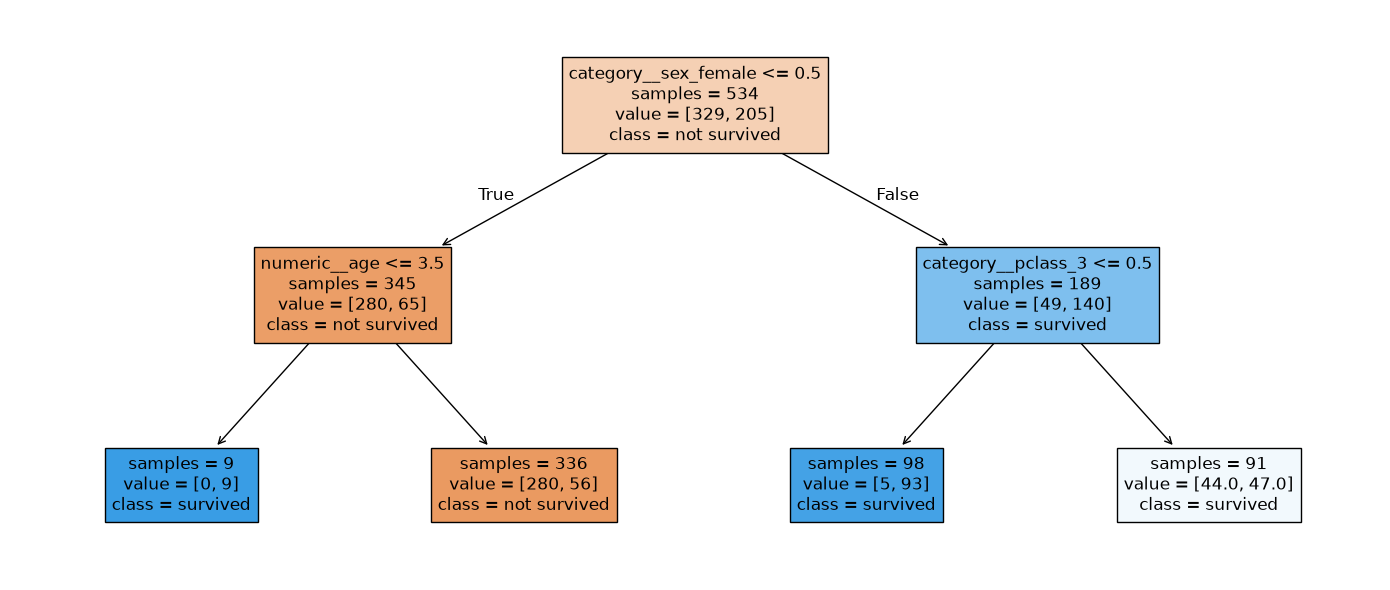

In [18]:
plt.figure(figsize=(14, 6))
# plot_tree: 학습한 트리의 분기 조건과 노드별 클래스 분포를 그린다.
plot_tree(
    tree_model, feature_names=feature_names,
    class_names=["not survived", "survived"], filled=True, impurity=False,
)
plt.tight_layout()
plt.show()


### F1으로 모델 평가하기

F1은 정밀도와 재현율을 하나의 점수로 요약한다.


In [19]:
name = "tree_depth2"
model = models[name]
# F1에는 클래스 예측값을 전달한다.
train_prediction = model.predict(X_train_processed)
val_prediction = model.predict(X_val_processed)
train_f1 = f1_score(y_train, train_prediction, zero_division=0)
val_f1 = f1_score(y_val, val_prediction, zero_division=0)
model_results[name] = {
    "model": name,
    "train_f1": train_f1,
    "val_f1": val_f1,
}

model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)


,model,train_f1,val_f1
0,tree_depth2,0.739454,0.753623
1,tree_depth3,0.733524,0.776860
2,tree_depth5,0.795640,0.750000
3,tree_unlimited,0.905371,0.721805


### 깊이와 과적합

트리가 깊어지면 더 많은 조건으로 데이터를 잘게 나눌 수 있다.
얕은 트리로 구분하기 어려웠던 사례도 나눌 수 있어, 더 복잡한 패턴을 학습할 수 있다.

분할을 계속하면 학습 데이터에만 나타나는 우연한 차이까지 조건에 반영할 수 있다.
이처럼 학습 데이터에 지나치게 맞춰져 새 데이터에서 예측 성능이 떨어지는 현상을 과적합이라고 한다.
학습 F1은 높아지는데 검증 F1이 낮아진다면 과적합의 징후로 볼 수 있다.

`max_depth`는 분기를 이어 갈 깊이를 제한하고, `min_samples_leaf`는 너무 적은 사례로 잎을 만드는 것을 제한한다.
두 설정으로 트리의 복잡도를 조절한다.

최대 깊이를 2·3·5·제한 없음으로 바꾸고 학습 F1과 검증 F1을 비교한다.
다른 설정과 학습·검증 데이터는 유지한다.


In [13]:
TREE_DEPTHS = [2, 3, 5, None]  # None은 최대 깊이를 제한하지 않는다.
depth_rows = []
for depth in TREE_DEPTHS:
    name = f"tree_depth{depth}" if depth is not None else "tree_unlimited"
    model = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=2, random_state=SEED,
    )
    model.fit(X_train_processed, y_train)
    models[name] = model
    train_prediction = model.predict(X_train_processed)
    val_prediction = model.predict(X_val_processed)
    train_f1 = f1_score(y_train, train_prediction, zero_division=0)
    val_f1 = f1_score(y_val, val_prediction, zero_division=0)
    model_results[name] = {
        "model": name,
        "train_f1": train_f1,
        "val_f1": val_f1,
    }
    depth_rows.append({
        **model_results[name],
        "actual_depth": model.get_depth(),  # 학습한 트리의 최대 깊이
        "leaves": model.get_n_leaves(),  # 학습한 트리의 잎 수
    })

depth_comparison = pd.DataFrame(depth_rows)
display(depth_comparison)


,model,train_f1,val_f1,actual_depth,leaves
0,tree_depth2,0.739454,0.753623,2,4
1,tree_depth3,0.733524,0.776860,3,7
2,tree_depth5,0.795640,0.750000,5,20
3,tree_unlimited,0.905371,0.721805,13,94


### 깊이별 결과 비교

가로축은 최대 깊이 설정, 세로축은 F1이다. 두 선은 같은 모델의 학습·검증 점수를 나타낸다.

현재 결과에서 깊이 제한이 없는 `Unlimited`는 깊이 5보다 학습 F1은 높고 검증 F1은 낮다.
학습 데이터에 더 잘 맞추면서 새 데이터에서의 성능은 떨어지는 과적합 양상을 확인할 수 있다.


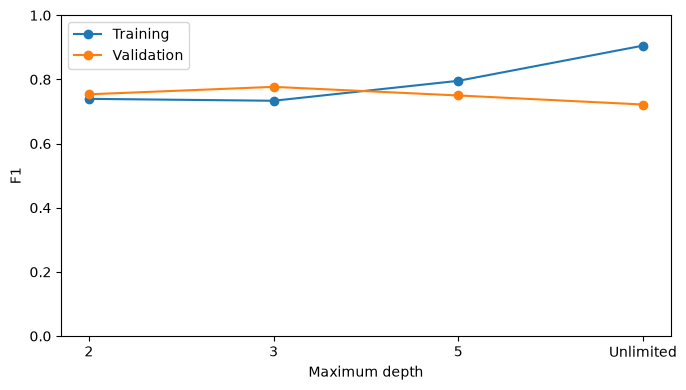

In [14]:
depth_labels = [str(depth) if depth is not None else "Unlimited" for depth in TREE_DEPTHS]
plt.figure(figsize=(7, 4))
plt.plot(depth_labels, depth_comparison["train_f1"], marker="o", label="Training")
plt.plot(depth_labels, depth_comparison["val_f1"], marker="o", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


## 랜덤포레스트

### 여러 트리의 예측 결합

결정 트리는 학습 데이터의 작은 변화에도 분기 구조와 예측 결과가 크게 달라질 수 있다.
랜덤포레스트는 여러 트리의 예측을 종합해 이러한 변동을 줄인다.
이처럼 여러 모델의 예측을 결합하는 방법을 앙상블(ensemble)이라고 한다.

랜덤포레스트는 두 가지 방식으로 서로 다른 트리를 만든다.

- 각 트리는 원본 학습 데이터에서 중복을 허용해 무작위로 뽑은 데이터로 학습한다.
- 각 노드를 분할할 때는 일부 특성을 무작위로 고른 뒤, 그 특성들을 대상으로 지니 불순도를 가장 많이 낮추는 분할 조건을 찾는다.

이렇게 학습한 트리들은 서로 다른 분기와 예측을 갖게 된다.
각 트리는 새 입력이 도달한 잎에서 학습 사례의 클래스 비율을 확률로 사용한다.
랜덤포레스트는 각 트리가 구한 클래스별 확률을 평균하고, 평균 확률이 가장 높은 클래스를 최종 예측으로 선택한다.


### 부트스트랩 표집

부트스트랩은 원본 데이터에서 중복을 허용해 데이터를 무작위로 뽑아 새로운 학습 데이터를 만드는 방법이다.
한 번 뽑힌 데이터도 다시 뽑을 수 있으므로, 같은 데이터가 여러 번 포함되거나 아예 포함되지 않을 수 있다.

랜덤포레스트는 각 트리에 사용할 학습 데이터를 부트스트랩을 통해 만든다.

아래 예제는 0부터 7까지의 숫자 중에서 중복을 허용해 8개를 부트스트랩으로 뽑는다.
뽑힌 숫자들을 출력하고, 서로 다른 숫자의 개수와 각 숫자가 뽑힌 횟수를 확인한다.


In [20]:
rng = np.random.default_rng(SEED)
row_positions = np.arange(8)
# replace=True: 같은 위치를 여러 번 뽑도록 허용한다.
sampled_positions = rng.choice(row_positions, size=8, replace=True)
print("뽑힌 위치:", sampled_positions)
print("고유 행 수:", len(np.unique(sampled_positions)))
display(pd.Series(sampled_positions).value_counts().reindex(row_positions, fill_value=0))


뽑힌 위치: [0 6 5 3 3 6 0 5]
고유 행 수: 4


0    2
1    0
2    0
3    2
4    0
5    2
6    2
7    0
Name: count, dtype: int64

### 트리 수 바꾸기

랜덤포레스트를 구성하는 트리 수를 1개·50개·100개로 바꾸어 학습 F1과 검증 F1을 비교한다.
각 트리의 최대 깊이는 5, 잎에 필요한 최소 학습 사례 수는 2로 고정하고, 나머지 조건도 동일하게 유지한다.

결과 표에는 깊이 5인 단일 결정 트리의 점수도 함께 표시한다.
트리 수가 늘어날 때 검증 성능이 어떻게 달라지는지 살펴본다.


In [ ]:
FOREST_TREE_COUNTS = [1, 50, 100]
# 비교 표의 첫 행에는 깊이 5인 단일 결정 트리의 평가 결과를 넣는다.
forest_rows = [model_results["tree_depth5"]]
for tree_count in FOREST_TREE_COUNTS:
    name = f"forest_{tree_count}"
    model = RandomForestClassifier(
        n_estimators=tree_count,  # 결합할 트리 수
        max_depth=5, min_samples_leaf=2,
        max_features="sqrt",  # 각 분할의 후보 특성 수: 전체 특성 수의 제곱근 기준
        bootstrap=True,  # 트리마다 중복을 허용해 학습 데이터를 뽑는다.
        random_state=SEED,
        n_jobs=1,  # 병렬 작업 수
    )
    model.fit(X_train_processed, y_train)
    models[name] = model  # 최종 모델 선택에 사용할 수 있도록 저장한다.
    train_prediction = model.predict(X_train_processed)
    val_prediction = model.predict(X_val_processed)
    train_f1 = f1_score(y_train, train_prediction, zero_division=0)
    val_f1 = f1_score(y_val, val_prediction, zero_division=0)
    model_results[name] = {
        "model": name,
        "train_f1": train_f1,
        "val_f1": val_f1,
    }
    forest_rows.append(model_results[name])  # 현재 트리 수의 평가 결과를 비교 표에 추가한다.

forest_comparison = pd.DataFrame(forest_rows)
display(forest_comparison)


,model,train_f1,val_f1
0,tree_depth5,0.795640,0.750000
1,forest_1,0.710744,0.704000
2,forest_50,0.784530,0.769231
3,forest_100,0.795640,0.769231


### 트리 수에 따른 결과 해석

현재 결과에서 포레스트의 트리 수를 1개에서 50개로 늘리면 검증 F1이 약 0.704에서 0.769로 높아진다.
100개일 때는 약 0.760으로, 이번 비교에서는 50개일 때 검증 F1이 가장 높다.
트리 수를 정할 때는 검증 성능과 학습·예측에 필요한 계산량을 함께 고려한다.


## Gradient Boosting

### 여러 트리로 예측을 보완하기

Gradient Boosting은 여러 트리를 순서대로 학습해 예측을 보완하는 앙상블 방법이다.
랜덤포레스트는 여러 트리의 예측 확률을 평균해 최종 클래스를 결정하고, Gradient Boosting은 초기 점수에 각 트리의 보정값을 학습률만큼 반영해 더한 결과로 최종 클래스를 결정한다.

Gradient Boosting에서 사용하는 각 트리는 클래스가 아니라 숫자 형태의 보정값을 출력한다.

### 학습할 때

먼저 학습 데이터의 클래스 비율을 바탕으로 초기 점수를 설정한다. 여기서 점수는 확률로 변환하기 전의 값이다.
현재 점수로 구한 예측 확률과 실제 정답을 비교해 손실을 계산한다.

그래디언트는 현재 예측 점수에서 손실이 가장 빠르게 증가하는 방향을 나타낸다. 손실을 줄이려면 그 반대인 음의 그래디언트 방향으로 점수를 보정한다.
새로운 트리는 각 학습 사례의 음의 그래디언트를 바탕으로 현재 예측 점수를 보완할 값을 학습한다.

새 트리가 만든 보정값을 학습률만큼 반영해 기존 점수에 더한다.
다음 트리는 지금까지 학습한 모든 트리의 보정이 반영된 점수를 기준으로 학습한다.

이 과정을 반복하며, 학습한 트리들은 모두 최종 모델에 포함된다.

### 예측할 때

새로운 입력을 학습된 모든 트리에 넣는다. 각 트리는 자신의 분기 조건에 따라 숫자 형태의 보정값을 출력한다.

초기 점수에 모든 트리의 보정값을 학습률만큼 반영해 더한다.
학습률이 0.1이라면 각 트리의 보정값에 0.1을 곱해 반영한다.

이진 분류에서는 합산한 점수에 시그모이드 함수를 적용해 클래스 1의 확률을 계산한다.
이 실습에서는 생존 확률을 의미하며, 해당 확률을 기준으로 최종 클래스를 결정한다.

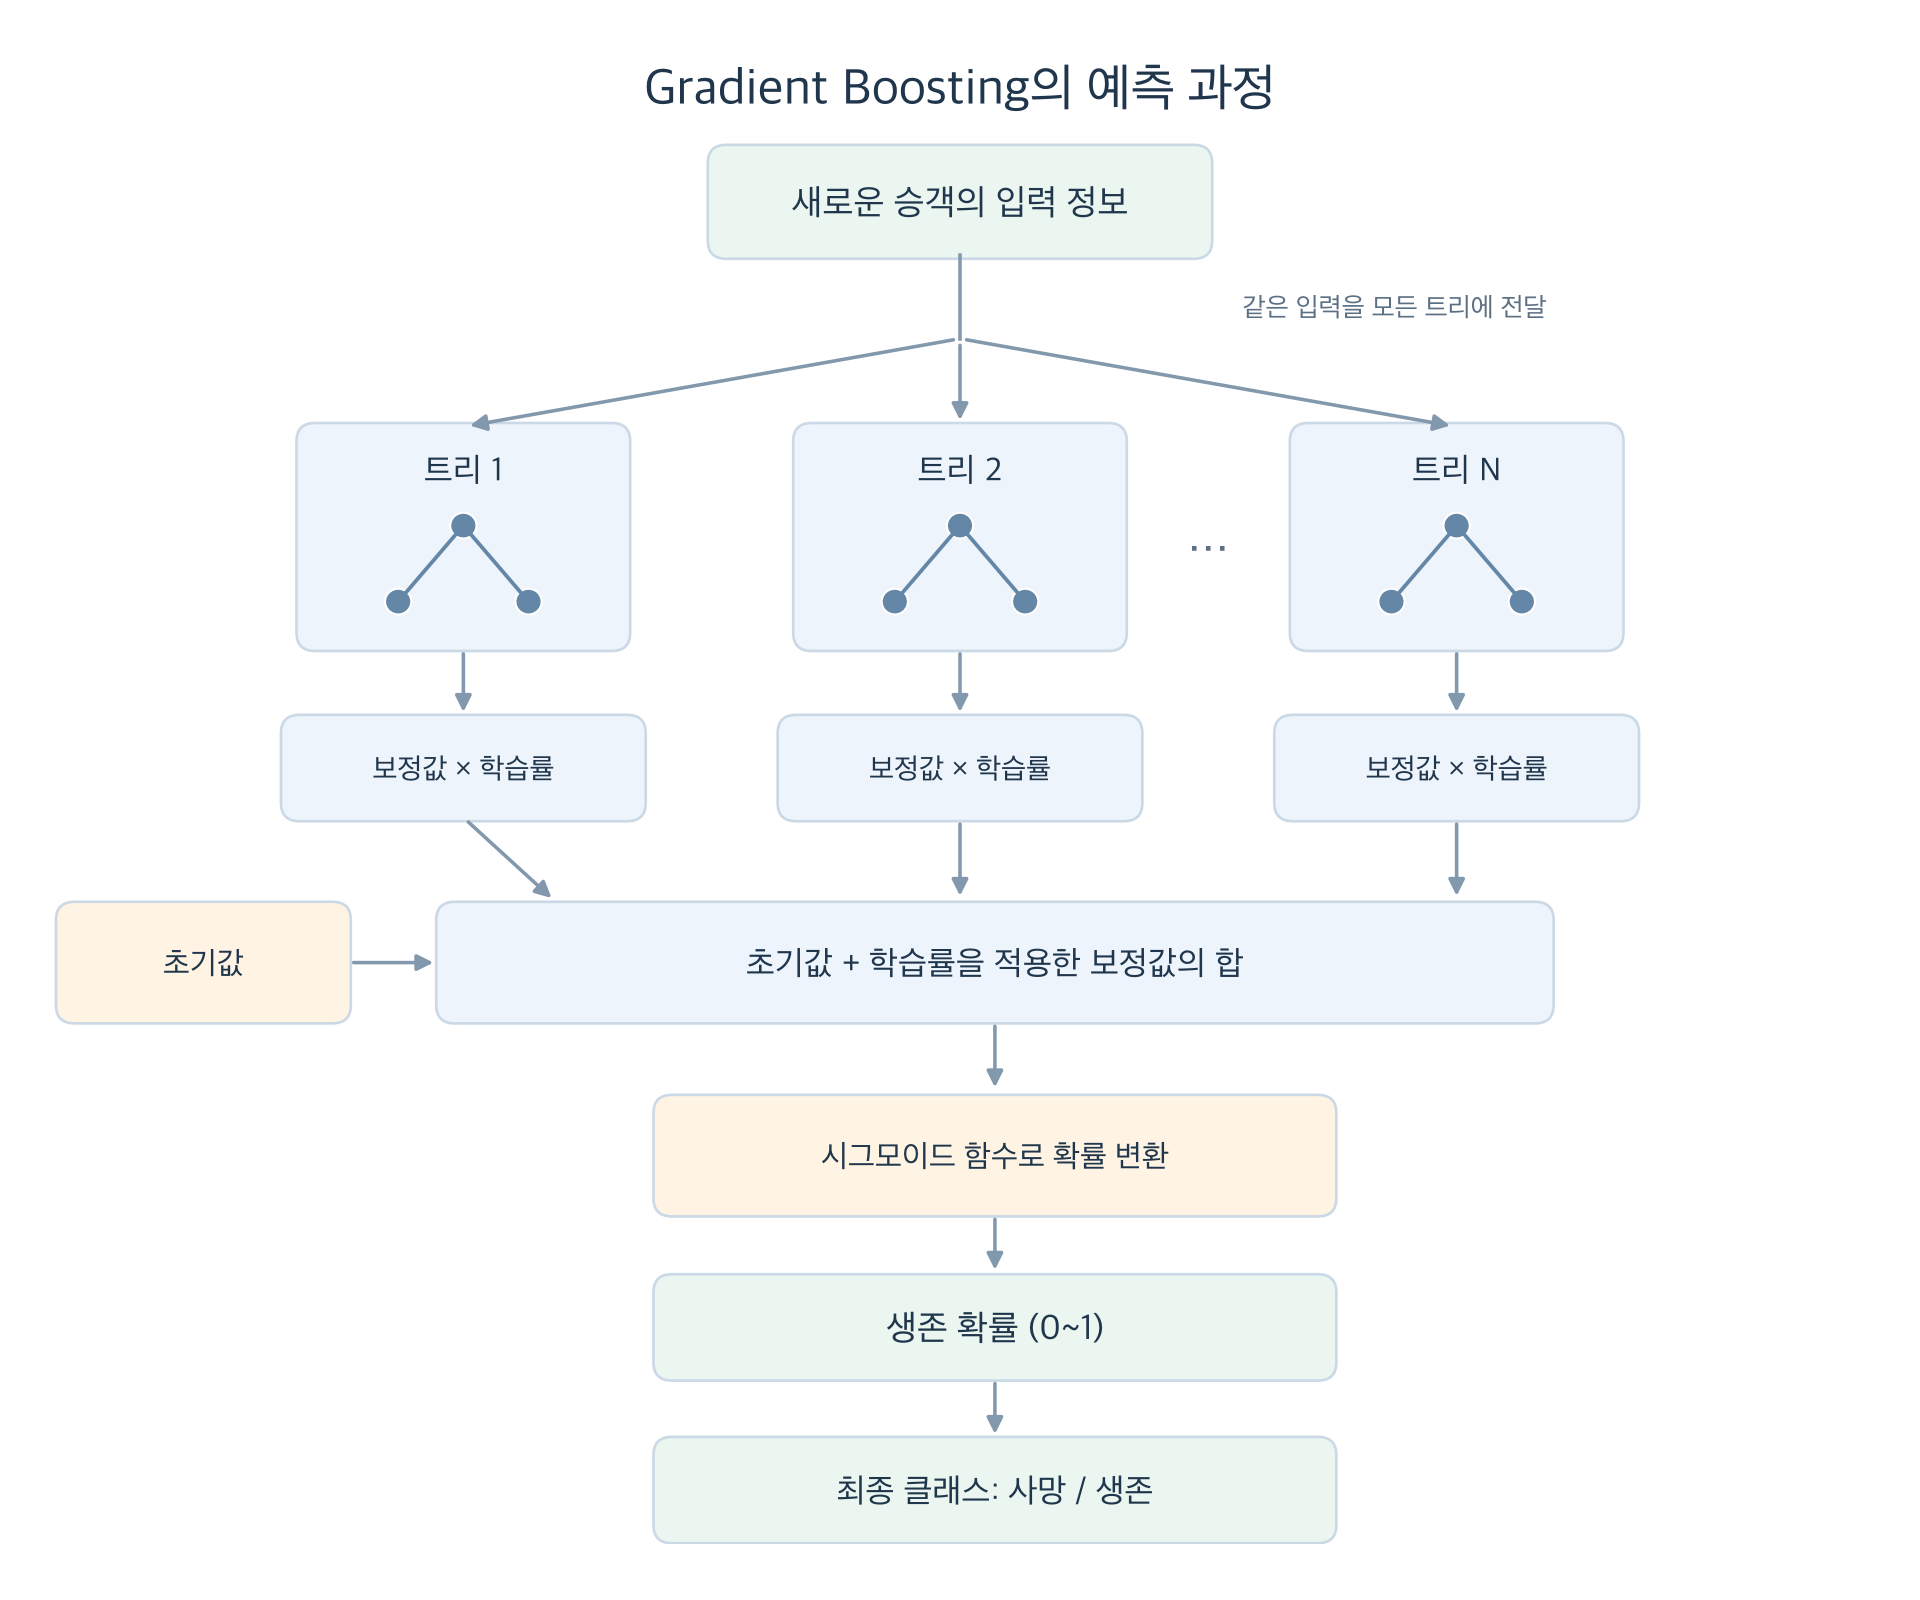


### 트리 수와 학습률 비교

`GradientBoostingClassifier`는 보정용 트리를 순서대로 학습해 분류하는 모델이다.
트리 수는 보정을 반복하는 횟수이고, 학습률은 각 보정을 반영하는 비율이다.
학습률이 작으면 한 단계의 변화가 작아져, 충분히 학습하는 데 더 많은 트리가 필요할 수 있다.

학습률 0.05·0.1과 트리 수 30·100·200을 조합해 학습 F1과 검증 F1을 비교한다.
각 트리의 최대 깊이는 2, 잎에 필요한 최소 학습 사례 수는 2로 고정한다.
학습률이 같을 때 트리 수의 영향을, 트리 수가 같을 때 학습률의 영향을 살펴본다.


In [22]:
BOOSTING_LEARNING_RATES = [0.05, 0.1]
BOOSTING_TREE_COUNTS = [30, 100, 200]
boosting_rows = []
for learning_rate in BOOSTING_LEARNING_RATES:
    for tree_count in BOOSTING_TREE_COUNTS:
        name = f"boost_lr{learning_rate}_trees{tree_count}"
        model = GradientBoostingClassifier(
            n_estimators=tree_count,  # 이진 분류의 보정 단계 수: 단계마다 트리 하나
            learning_rate=learning_rate,  # 각 트리 보정값에 곱하는 비율
            max_depth=2, min_samples_leaf=2, random_state=SEED,
        )
        model.fit(X_train_processed, y_train)
        models[name] = model
        train_prediction = model.predict(X_train_processed)
        val_prediction = model.predict(X_val_processed)
        train_f1 = f1_score(y_train, train_prediction, zero_division=0)
        val_f1 = f1_score(y_val, val_prediction, zero_division=0)
        model_results[name] = {
            "model": name,
            "train_f1": train_f1,
            "val_f1": val_f1,
        }
        boosting_rows.append(model_results[name])

boosting_comparison = pd.DataFrame(boosting_rows)
display(boosting_comparison)


,model,train_f1,val_f1
0,boost_lr0.05_trees30,0.752809,0.758065
1,boost_lr0.05_trees100,0.776536,0.768000
2,boost_lr0.05_trees200,0.834688,0.781955
3,boost_lr0.1_trees30,0.759777,0.758065
4,boost_lr0.1_trees100,0.832000,0.787879
5,boost_lr0.1_trees200,0.871134,0.811594


### 단계별 학습·검증 손실

트리를 추가할 때마다 예측이 어떻게 달라지는지 로그 손실로 확인한다.
로그 손실은 로지스틱 회귀에서도 사용하는 손실함수로, 예측 확률이 정답에 얼마나 잘 맞는지 측정한다. 값이 낮을수록 좋다.
정답 클래스에 높은 확률을 줄수록 손실이 작고, 틀린 클래스에 높은 확률을 줄수록 손실이 커진다.
F1은 최종 클래스 예측을 평가하고, 로그 손실은 예측 확률을 평가한다.

그래프의 가로축은 추가한 트리 수, 세로축은 로그 손실이다.
학습률별로 200개의 트리를 학습한 모델에서 단계별 손실을 계산하고, 검증 손실이 가장 낮은 위치를 점선으로 표시한다.
현재 결과에서는 학습률 0.05가 197단계, 0.1이 172단계에서 검증 손실이 가장 낮다.

- 학습 손실이 더 빠르게 줄어도 검증 손실이 함께 감소하면, 검증 데이터에서도 예측이 개선되고 있다. 두 손실의 차이와 검증 손실의 추세를 함께 살펴본다.
- 학습 손실은 계속 낮아지는데 검증 손실이 상승하면 과적합의 징후로 볼 수 있다. 이때 `max_depth`를 낮춰 각 트리를 단순하게 만드는 실험을 할 수 있다.
- 깊이를 바꾼 뒤에는 손실 곡선과 검증 F1을 비교한다. 검증 로그 손실이 최소인 설정과 검증 F1이 최대인 설정은 다를 수 있으며, 이 실습에서는 검증 F1을 기준으로 모델을 선택한다.


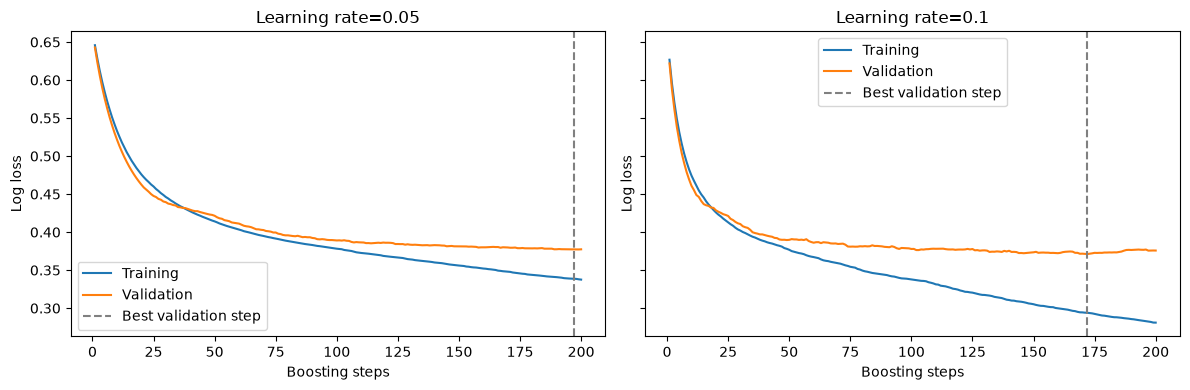

,learning_rate,best_step,best_val_loss,last_val_loss
0,0.05,197,0.377150,0.377393
1,0.10,172,0.371161,0.375781


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
loss_rows = []
for ax, rate in zip(axes, BOOSTING_LEARNING_RATES):
    curve_model = models[f"boost_lr{rate}_trees200"]
    # staged_predict_proba: 각 단계의 (승객 수, 클래스 수) 확률 배열을 차례로 반환한다.
    # log_loss: 정답과 클래스별 예측 확률을 받아 평균 로그 손실을 반환한다.
    train_loss = [log_loss(y_train, probabilities) for probabilities in
                  curve_model.staged_predict_proba(X_train_processed)]
    val_loss = [log_loss(y_val, probabilities) for probabilities in
                curve_model.staged_predict_proba(X_val_processed)]
    steps = np.arange(1, len(train_loss) + 1)
    best_step = int(np.argmin(val_loss)) + 1  # 배열 위치는 0, 보정 단계는 1부터 시작
    ax.plot(steps, train_loss, label="Training")
    ax.plot(steps, val_loss, label="Validation")
    ax.axvline(best_step, color="gray", linestyle="--", label="Best validation step")
    ax.set(title=f"Learning rate={rate}", xlabel="Boosting steps", ylabel="Log loss")
    ax.legend()
    loss_rows.append({
        "learning_rate": rate, "best_step": best_step,
        "best_val_loss": min(val_loss), "last_val_loss": val_loss[-1],
    })
plt.tight_layout()
plt.show()
display(pd.DataFrame(loss_rows))


### 보정 트리의 깊이 바꾸기

각 트리의 깊이는 한 번의 보정에서 얼마나 복잡한 패턴을 학습할지 결정한다.
깊이가 깊어지면 세밀한 보정이 가능해지고, 학습 데이터의 우연한 차이까지 반영할 수 있다.

학습률 0.1, 트리 수 100, 최소 잎 사례 수 2를 유지하고 최대 깊이를 2에서 3으로 바꾼다.
두 모델의 학습 F1과 검증 F1을 비교한다.


In [24]:
deeper_boosting_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1,
    max_depth=3, min_samples_leaf=2, random_state=SEED,
)
deeper_boosting_model.fit(X_train_processed, y_train)
models["boost_depth3"] = deeper_boosting_model

name = "boost_depth3"
model = deeper_boosting_model
train_prediction = model.predict(X_train_processed)
val_prediction = model.predict(X_val_processed)
train_f1 = f1_score(y_train, train_prediction, zero_division=0)
val_f1 = f1_score(y_val, val_prediction, zero_division=0)
model_results[name] = {
    "model": name,
    "train_f1": train_f1,
    "val_f1": val_f1,
}

display(pd.DataFrame([
    model_results["boost_lr0.1_trees100"],
    model_results["boost_depth3"],
]))


,model,train_f1,val_f1
0,boost_lr0.1_trees100,0.832000,0.787879
1,boost_depth3,0.868421,0.812030


### 보정 트리 깊이에 따른 결과 해석

현재 결과에서 깊이를 2에서 3으로 늘리면 학습 F1은 약 0.832에서 0.868로, 검증 F1은 약 0.788에서 0.812로 높아진다.
이번 비교에서는 깊이 3인 모델의 검증 성능이 더 좋다.
깊이에 따른 성능 변화는 데이터와 설정에 따라 달라지므로 학습 점수와 검증 점수를 함께 확인한다.


## 트리 앙상블 모델 비교와 선택

결정 트리·랜덤포레스트·Gradient Boosting의 검증 결과를 비교한다.
모든 후보는 같은 입력과 전처리 결과를 사용한다. 각 모델의 설정과 학습 방식이 함께 다르므로 현재 조건에서의 결과로 해석한다.

검증 F1이 가장 높은 모델을 선택한다. 동점이면 먼저 등록된 후보를 사용한다.
학습·검증 F1 차이도 함께 읽고, 선택된 모델과 다른 계열의 모델 하나를 비교해 선택 이유를 적는다.
테스트 구간은 모델 선택에 사용하지 않는다.


In [25]:
model_comparison = pd.DataFrame(model_results.values())
# 검증 F1을 내림차순 정렬한다. 동점인 행은 등록 순서를 유지한다.
model_comparison = model_comparison.sort_values(
    "val_f1", ascending=False, kind="stable",
)
display(model_comparison)
selected_name = model_comparison.iloc[0]["model"]
selected_model = models[selected_name]
print("선택한 모델:", selected_name)


,model,train_f1,val_f1
13,boost_depth3,0.868421,0.812030
12,boost_lr0.1_trees200,0.871134,0.811594
11,boost_lr0.1_trees100,0.832000,0.787879
9,boost_lr0.05_trees200,0.834688,0.781955
1,tree_depth3,0.733524,0.776860
5,forest_50,0.784530,0.769231
6,forest_100,0.795640,0.769231
8,boost_lr0.05_trees100,0.776536,0.768000
7,boost_lr0.05_trees30,0.752809,0.758065
10,boost_lr0.1_trees30,0.759777,0.758065


선택한 모델: boost_depth3


### 최종 테스트

검증 결과로 선택한 모델의 학습·테스트 F1을 한 표로 확인한다.
학습한 전처리 기준과 모델을 그대로 사용하며, 테스트 결과로 모델이나 설정을 다시 고르지 않는다.


In [26]:
X_test_processed = preprocessor.transform(X_test)
final_train_prediction = selected_model.predict(X_train_processed)
test_prediction = selected_model.predict(X_test_processed)

final_rows = []
for split, actual, prediction in [
    ("train", y_train, final_train_prediction),
    ("test", y_test, test_prediction),
]:
    final_rows.append({
        "split": split,
        "F1": f1_score(actual, prediction, zero_division=0),
    })
final_comparison = pd.DataFrame(final_rows)
print("선택 모델:", selected_name)
display(final_comparison)


선택 모델: boost_depth3


,split,F1
0,train,0.868421
1,test,0.723077


### 학습·테스트 결과 해석

- 학습 성능에 비해 테스트 성능이 낮아 과적합의 징후가 보인다. 학습·검증 성능은 비슷한데 테스트에서 더 크게 낮아졌다면, 데이터 수에 따른 점수 변동, 분할된 데이터의 특성 차이, 검증 데이터에 유리한 모델이 선택되었을 가능성을 함께 살펴본다.

- 테스트 점수가 낮다는 이유로 검증 2위 모델로 바꾸면 테스트 결과가 모델 선택에 관여한다. 같은 테스트 데이터로 다시 평가한 점수에는 선택 과정의 영향이 반영되므로, 독립적인 최종 평가로 보기 어렵다.

- 테스트를 보기 전에 학습·검증 결과만으로 검증 2위 모델을 선택하는 것은 가능하다. 검증 점수 차이가 작다면 학습·검증 성능 차이나 모델 복잡도를 고려할 수 있으며, 선택 기준은 테스트를 보기 전에 정한다.

- F1과 함께 정밀도·재현율·혼동 행렬을 확인해 어떤 오류가 늘었는지 살펴본다. 데이터 분할과 전처리 과정을 점검하고, 각 구간의 사례 수·클래스 비율·입력 특성 분포도 비교한다. 이 결과로 모델을 수정하면 테스트도 개발 과정에 사용된 것으로 본다.


## 연습문제: 유방암 악성 여부 예측

### 유방암 진단 데이터 불러오기

Wisconsin 유방암 진단 데이터는 검체 569개의 세포핵 측정값과 진단 결과를 담고 있으며, 한 행은 검체 하나다. 30개 수치형 특성으로 악성 여부를 예측하는 이진 분류 문제다. 악성 212개와 양성 종양 357개로 구성되며, 악성(1)을 양성 클래스로 사용한다.

측정 항목은 반지름·질감·둘레·면적·매끄러움·조밀함·오목함·오목한 부분의 수·대칭성·윤곽의 복잡도다. 반지름은 중심에서 윤곽까지의 거리, 질감은 영상의 밝기 값이 변하는 정도를 나타낸다. 각 항목을 평균·표준오차·큰 값으로 요약해 30개 입력 특성을 구성하며, 결측값은 없다.

| 역할 | 열 | 의미 |
| --- | --- | --- |
| 숫자 입력 | `mean ...` | 각 측정 항목의 평균. 예: `mean radius`, `mean texture` |
| 숫자 입력 | `... error` | 평균 추정의 변동성을 나타내는 표준오차. 예: `radius error` |
| 숫자 입력 | `worst ...` | 가장 큰 측정값 3개의 평균. 예: `worst radius` |
| 정답 | `malignant` | 악성 1, 양성 종양 0 |


In [ ]:
from sklearn.datasets import load_breast_cancer

# as_frame=True: 입력은 DataFrame, 정답은 Series로 불러온다.
exercise_cancer = load_breast_cancer(as_frame=True)
exercise_X = exercise_cancer.data.copy()  # (569, 30)
# 원본의 악성 0을 1로, 양성 종양 1을 0으로 바꾼다.
exercise_y = (exercise_cancer.target == 0).astype(int).rename("malignant")


### 직접 작성하기: 결정 트리 기반 방법으로 악성 여부 예측

유방암 진단 데이터를 바탕으로 결정 트리 기반 방법을 활용해 악성 여부를 예측하고, 모델의 성능을 평가해 보세요.
